Saving 3a3d4b04d70cc293fadf195b4e1a7bcb.jpg to 3a3d4b04d70cc293fadf195b4e1a7bcb.jpg
Image uploaded: 3a3d4b04d70cc293fadf195b4e1a7bcb.jpg
Image dimensions: (564, 705)
Maximum message capacity: 149103 bytes


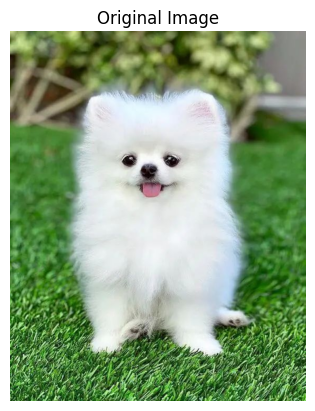

In [1]:
from google.colab import files
from PIL import Image
import numpy as np
import io
import matplotlib.pyplot as plt

# Upload an image
uploaded = files.upload()

filename = next(iter(uploaded))
image = Image.open(io.BytesIO(uploaded[filename])).convert("RGB")
img_array = np.array(image)

print("Image uploaded:", filename)
print("Image dimensions:", image.size)
print("Maximum message capacity:", (img_array.size - 32) // 8, "bytes")

plt.imshow(image)
plt.axis("off")
plt.title("Original Image")
plt.show()

Enter the message to hide: This is a secret message!
Message hidden successfully!
Encoded image saved as: stego_image.png


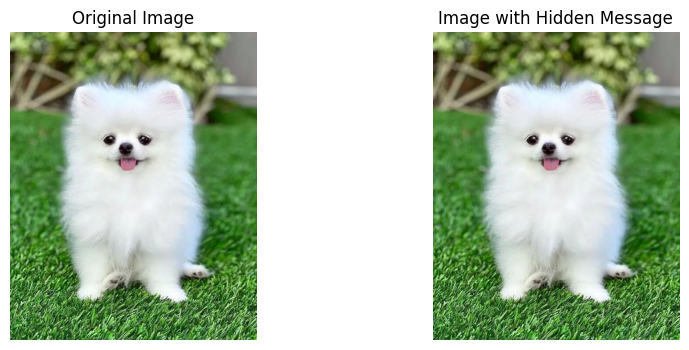

In [2]:
def encode_message(image_array, message):
    # Convert message to binary
    message_bytes = message.encode("utf-8")
    message_bits = ''.join(format(byte, '08b') for byte in message_bytes)

    # Store message length in the first 32 bits
    length_bits = format(len(message_bytes), '032b')
    binary_data = length_bits + message_bits

    # Check image capacity
    if len(binary_data) > image_array.size:
        raise ValueError("Message too long for this image!")

    # Copy image and flatten pixel channels
    encoded = image_array.copy().flatten()

    # Hide data in the least significant bits
    for i, bit in enumerate(binary_data):
        encoded[i] = (encoded[i] & 254) | int(bit)

    return encoded.reshape(image_array.shape)


# Enter your secret message
secret_message = input("Enter the message to hide: ")

# Encode the message
encoded_array = encode_message(img_array, secret_message)
encoded_image = Image.fromarray(encoded_array)

# Save as PNG to preserve hidden bits
output_file = "stego_image.png"
encoded_image.save(output_file, format="PNG")

print("Message hidden successfully!")
print("Encoded image saved as:", output_file)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(encoded_image)
plt.title("Image with Hidden Message")
plt.axis("off")

plt.show()

In [3]:
def decode_message(image_array):
    flat = image_array.flatten()

    # Read the first 32 bits to determine message length
    length_bits = ''.join(str(int(pixel) & 1) for pixel in flat[:32])
    message_length = int(length_bits, 2)

    # Validate message length
    if 32 + message_length * 8 > len(flat):
        raise ValueError("No valid message found in this image.")

    # Extract message bits
    message_bits = ''.join(
        str(int(pixel) & 1)
        for pixel in flat[32:32 + message_length * 8]
    )

    # Convert bits back to bytes and decode
    message_bytes = bytes(
        int(message_bits[i:i + 8], 2)
        for i in range(0, len(message_bits), 8)
    )

    return message_bytes.decode("utf-8")


# Decode directly from the encoded image
decoded_message = decode_message(np.array(encoded_image))

print("Extracted secret message:")
print(decoded_message)

assert decoded_message == secret_message
print("\nVerification successful! The message matches.")

Extracted secret message:
This is a secret message!

Verification successful! The message matches.


In [ ]:
files.download("stego_image.png")

Saving 3a3d4b04d70cc293fadf195b4e1a7bcb.jpg to 3a3d4b04d70cc293fadf195b4e1a7bcb (1).jpg
Image: 3a3d4b04d70cc293fadf195b4e1a7bcb (1).jpg
Dimensions: 564 × 705
Maximum raw message capacity: 149103 bytes


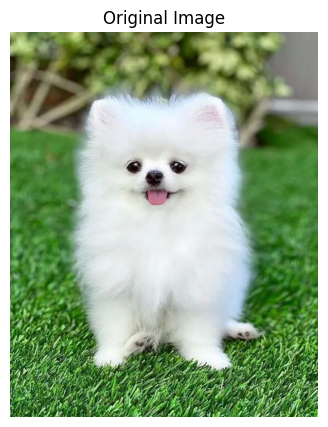

In [4]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import base64

uploaded = files.upload()
filename = next(iter(uploaded))

original = Image.open(filename).convert("RGB")
img = np.array(original, dtype=np.uint8)

print(f"Image: {filename}")
print(f"Dimensions: {original.width} × {original.height}")
print(f"Maximum raw message capacity: {max(0, (img.size - 32) // 8)} bytes")

plt.figure(figsize=(7, 5))
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [5]:
def xor_transform(data, key):
    """Reversible XOR transformation."""
    key_bytes = key.encode("utf-8")
    if not key_bytes:
        raise ValueError("XOR key cannot be empty.")

    return bytes(
        byte ^ key_bytes[i % len(key_bytes)]
        for i, byte in enumerate(data)
    )


def encode_image(image_array, payload):
    """Hide bytes using LSB; first 32 bits store payload length."""
    bits = ''.join(f'{byte:08b}' for byte in payload)
    header = f'{len(payload):032b}'
    binary = header + bits

    if len(binary) > image_array.size:
        raise ValueError(
            f"Message too large! Need {len(binary)} bits, "
            f"but image holds {image_array.size} bits."
        )

    result = image_array.copy().flatten()
    for i, bit in enumerate(binary):
        result[i] = (result[i] & 254) | int(bit)

    return result.reshape(image_array.shape)


def decode_image(encoded_array):
    """Recover hidden bytes from an LSB-encoded image."""
    flat = encoded_array.flatten()

    length_bits = ''.join(str(int(x) & 1) for x in flat[:32])
    length = int(length_bits, 2)

    if 32 + length * 8 > len(flat):
        raise ValueError("Invalid or corrupted hidden message.")

    bits = ''.join(
        str(int(x) & 1)
        for x in flat[32:32 + length * 8]
    )

    return bytes(
        int(bits[i:i + 8], 2)
        for i in range(0, len(bits), 8)
    )


def method_raw(message):
    """Method 1: Raw UTF-8 encoding."""
    return message.encode("utf-8")


def method_base64(message):
    """Method 2: Base64 encoding."""
    return base64.b64encode(message.encode("utf-8"))


def method_xor(message, key):
    """Method 3: XOR transformation."""
    return xor_transform(message.encode("utf-8"), key)


def decode_raw(payload):
    return payload.decode("utf-8")


def decode_base64(payload):
    return base64.b64decode(payload, validate=True).decode("utf-8")


def decode_xor(payload, key):
    return xor_transform(payload, key).decode("utf-8")


print("Three encoding/decoding methods are ready!")

Three encoding/decoding methods are ready!


In [6]:
secret_message = input("Enter your secret message: ")
xor_key = input("Enter an XOR key (e.g., blue7): ")

methods = {
    "Raw UTF-8 + LSB": (
        method_raw(secret_message),
        decode_raw
    ),
    "Base64 + LSB": (
        method_base64(secret_message),
        decode_base64
    ),
    "XOR + LSB": (
        method_xor(secret_message, xor_key),
        decode_xor
    )
}

encoded_images = {}
decoded_messages = {}

for name, (payload, decoder) in methods.items():
    try:
        encoded = encode_image(img, payload)
        recovered = decode_image(encoded)

        if name == "XOR + LSB":
            decoded = decoder(recovered, xor_key)
        else:
            decoded = decoder(recovered)

        encoded_images[name] = encoded
        decoded_messages[name] = decoded

        print(f"\n{name}")
        print(f"Encoded payload size: {len(payload)} bytes")
        print(f"Decoded message: {decoded}")
        print(f"Verification: {'PASS' if decoded == secret_message else 'FAIL'}")

    except Exception as e:
        print(f"\n{name}: {e}")

Enter your secret message: This is a secret text!
Enter an XOR key (e.g., blue7): blue7

Raw UTF-8 + LSB
Encoded payload size: 22 bytes
Decoded message: This is a secret text!
Verification: PASS

Base64 + LSB
Encoded payload size: 32 bytes
Decoded message: This is a secret text!
Verification: PASS

XOR + LSB
Encoded payload size: 22 bytes
Decoded message: This is a secret text!
Verification: PASS


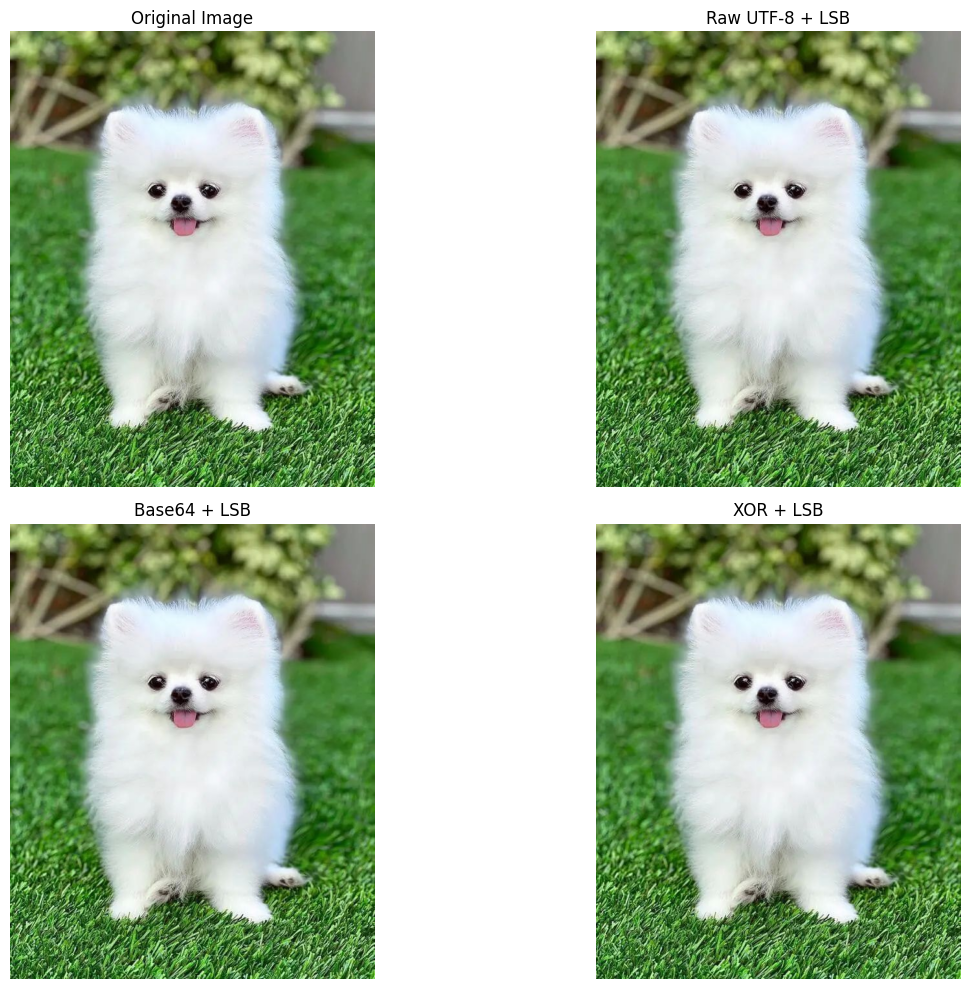

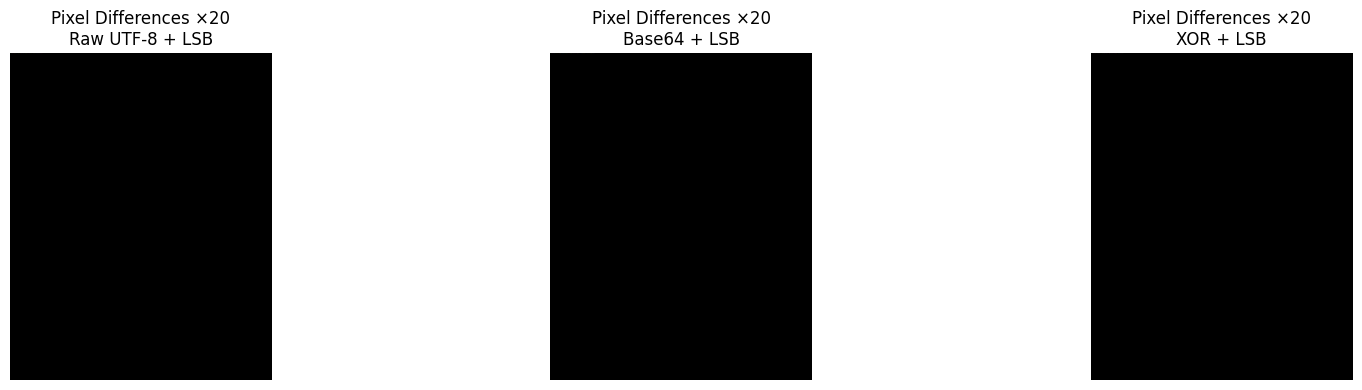

In [7]:
available = list(encoded_images.items())

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].imshow(img)
axes[0, 0].set_title("Original Image")

for ax, (name, encoded) in zip(axes.flat[1:], available):
    ax.imshow(encoded)
    ax.set_title(name)

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()


# Pixel difference visualization
fig, axes = plt.subplots(1, len(available), figsize=(6 * len(available), 4))

if len(available) == 1:
    axes = [axes]

for ax, (name, encoded) in zip(axes, available):
    difference = np.abs(
        img.astype(np.int16) - encoded.astype(np.int16)
    )

    ax.imshow(difference * 20)
    ax.set_title(f"Pixel Differences ×20\n{name}")
    ax.axis("off")

plt.tight_layout()
plt.show()

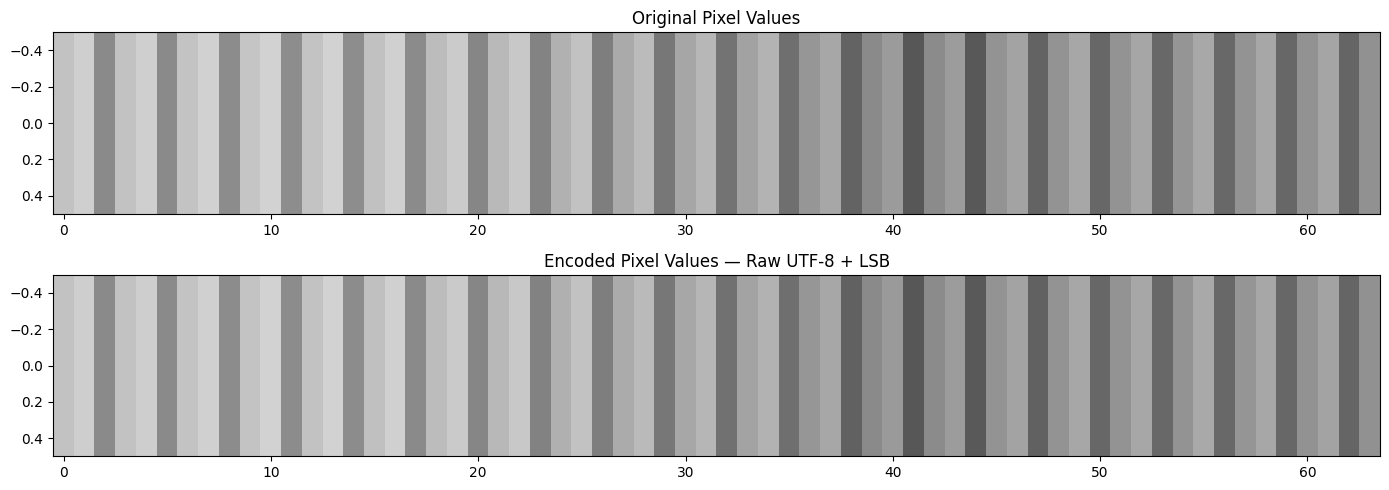

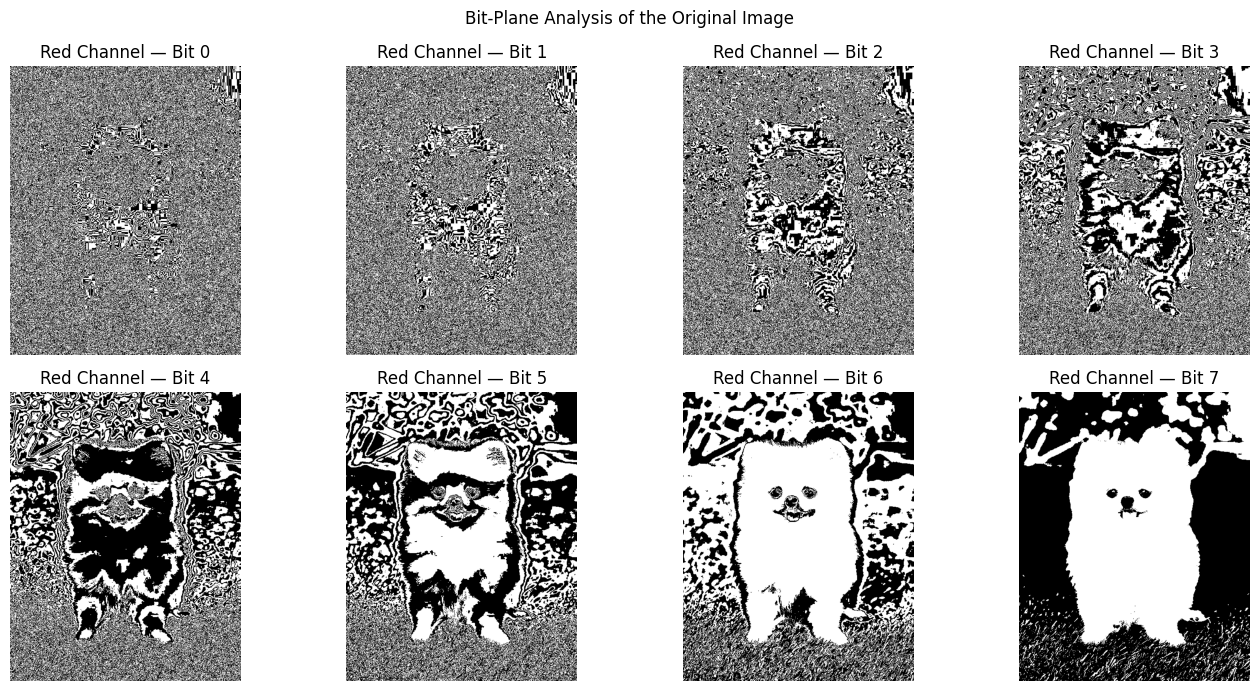

In [8]:
# Display the first 64 pixel-channel values before and after encoding
if encoded_images:
    name = next(iter(encoded_images))
    encoded = encoded_images[name]

    original_values = img.flatten()[:64]
    encoded_values = encoded.flatten()[:64]

    fig, axes = plt.subplots(2, 1, figsize=(14, 5))

    axes[0].imshow(
        original_values.reshape(1, -1),
        cmap="gray",
        aspect="auto",
        vmin=0,
        vmax=255
    )
    axes[0].set_title("Original Pixel Values")

    axes[1].imshow(
        encoded_values.reshape(1, -1),
        cmap="gray",
        aspect="auto",
        vmin=0,
        vmax=255
    )
    axes[1].set_title(f"Encoded Pixel Values — {name}")

    plt.tight_layout()
    plt.show()


# Visualize individual bit planes of the original image
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for bit in range(8):
    plane = (img[:, :, 0] >> bit) & 1

    ax = axes.flat[bit]
    ax.imshow(plane, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Red Channel — Bit {bit}")
    ax.axis("off")

plt.suptitle("Bit-Plane Analysis of the Original Image")
plt.tight_layout()
plt.show()

In [9]:
print("ENCODING / DECODING COMPARISON")
print("-" * 60)

for name, (payload, _) in methods.items():
    if name not in encoded_images:
        print(f"{name}: Could not encode (capacity exceeded).")
        continue

    recovered = decode_image(encoded_images[name])

    if name == "XOR + LSB":
        final_message = decode_xor(recovered, xor_key)
    elif name == "Base64 + LSB":
        final_message = decode_base64(recovered)
    else:
        final_message = decode_raw(recovered)

    print(f"\nMethod: {name}")
    print(f"Payload bytes: {len(payload)}")
    print(f"Recovered correctly: {final_message == secret_message}")


# Select which encoded image to download
if encoded_images:
    print("\nAvailable methods:")
    names = list(encoded_images.keys())

    for i, name in enumerate(names, 1):
        print(f"{i}. {name}")

    choice = int(input("Choose an image to download (enter number): "))

    if 1 <= choice <= len(names):
        selected_name = names[choice - 1]
        output_name = f"stego_{choice}.png"

        Image.fromarray(
            encoded_images[selected_name]
        ).save(output_name, format="PNG")

        files.download(output_name)
        print(f"Downloaded: {output_name}")
    else:
        print("Invalid selection.")

ENCODING / DECODING COMPARISON
------------------------------------------------------------

Method: Raw UTF-8 + LSB
Payload bytes: 22
Recovered correctly: True

Method: Base64 + LSB
Payload bytes: 32
Recovered correctly: True

Method: XOR + LSB
Payload bytes: 22
Recovered correctly: True

Available methods:
1. Raw UTF-8 + LSB
2. Base64 + LSB
3. XOR + LSB
Choose an image to download (enter number): 3


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: stego_3.png


Available encoding methods:
1. Raw UTF-8 + LSB
2. Base64 + LSB
3. XOR + LSB
Choose a method to visualize: 3


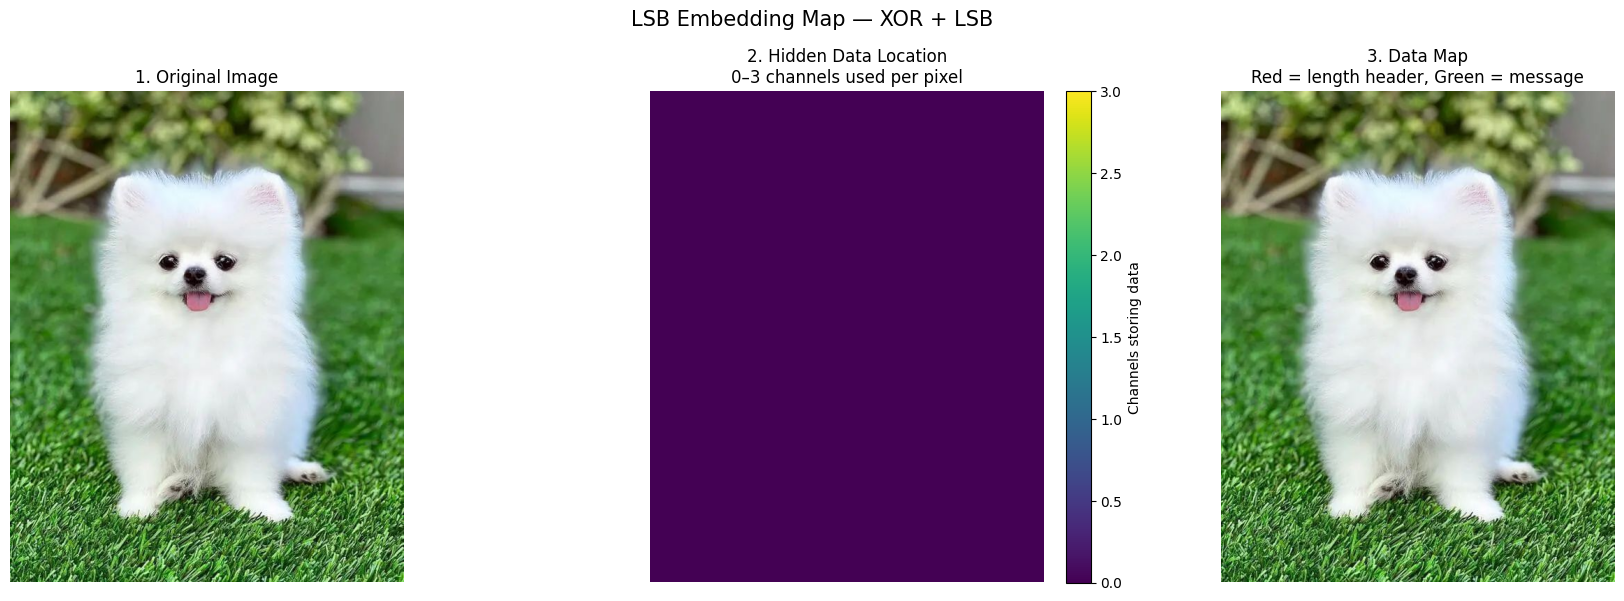


FIRST 32 EMBEDDED BITS
Position | Pixel (x,y) | Channel | Before | After | Hidden bit
       0 | (   0,    0) |    R    |    194 |   194 | 0
       1 | (   0,    0) |    G    |    207 |   206 | 0
       2 | (   0,    0) |    B    |    138 |   138 | 0
       3 | (   1,    0) |    R    |    194 |   194 | 0
       4 | (   1,    0) |    G    |    207 |   206 | 0
       5 | (   1,    0) |    B    |    138 |   138 | 0
       6 | (   2,    0) |    R    |    196 |   196 | 0
       7 | (   2,    0) |    G    |    209 |   208 | 0
       8 | (   2,    0) |    B    |    140 |   140 | 0
       9 | (   3,    0) |    R    |    197 |   196 | 0
      10 | (   3,    0) |    G    |    210 |   210 | 0
      11 | (   3,    0) |    B    |    141 |   140 | 0
      12 | (   4,    0) |    R    |    195 |   194 | 0
      13 | (   4,    0) |    G    |    210 |   210 | 0
      14 | (   4,    0) |    B    |    141 |   140 | 0
      15 | (   5,    0) |    R    |    193 |   192 | 0
      16 | (   5,    0) |    G   

In [12]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Select an encoding method that succeeded
available_names = list(encoded_images.keys())

print("Available encoding methods:")
for i, name in enumerate(available_names, 1):
    print(f"{i}. {name}")

choice = int(input("Choose a method to visualize: ")) - 1
method_name = available_names[choice]

encoded = encoded_images[method_name]
payload = methods[method_name][0]

# 32-bit header + message payload
total_bits = 32 + len(payload) * 8
height, width, _ = img.shape

# Each flattened position represents one RGB channel
positions = np.arange(total_bits)
pixel_indices = positions // 3
channels = positions % 3

ys = pixel_indices // width
xs = pixel_indices % width

# Count how many channels in each pixel store data
occupancy = np.zeros((height, width), dtype=np.uint8)
np.add.at(occupancy, (ys, xs), 1)

# Mark header and payload locations separately
header_mask = np.zeros((height, width), dtype=bool)
message_mask = np.zeros((height, width), dtype=bool)

header_mask[ys[:32], xs[:32]] = True
message_mask[ys[32:], xs[32:]] = True

# Show the original image and hidden-data locations
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(img)
axes[0].set_title("1. Original Image")

axes[1].imshow(occupancy, cmap="viridis", vmin=0, vmax=3)
axes[1].set_title("2. Hidden Data Location\n0–3 channels used per pixel")
plt.colorbar(
    plt.cm.ScalarMappable(
        cmap="viridis",
        norm=plt.Normalize(0, 3)
    ),
    ax=axes[1],
    fraction=0.046,
    pad=0.04,
    label="Channels storing data"
)

axes[2].imshow(img)
axes[2].imshow(
    np.ma.masked_where(~header_mask, header_mask),
    cmap=ListedColormap(["red"]),
    alpha=0.9
)
axes[2].imshow(
    np.ma.masked_where(~message_mask, message_mask),
    cmap=ListedColormap(["lime"]),
    alpha=0.55
)
axes[2].set_title("3. Data Map\nRed = length header, Green = message")

for ax in axes:
    ax.axis("off")

plt.suptitle(f"LSB Embedding Map — {method_name}", fontsize=15)
plt.tight_layout()
plt.show()

# Show exact channel-level changes for the first 32 embedded bits
print("\nFIRST 32 EMBEDDED BITS")
print("Position | Pixel (x,y) | Channel | Before | After | Hidden bit")

original_flat = img.flatten()
encoded_flat = encoded.flatten()

for i in range(min(32, total_bits)):
    channel_name = ["R", "G", "B"][channels[i]]
    hidden_bit = int(encoded_flat[i] & 1)

    print(
        f"{i:8} | ({xs[i]:4}, {ys[i]:4}) | "
        f"{channel_name:^7} | {original_flat[i]:6} | "
        f"{encoded_flat[i]:5} | {hidden_bit}"
    )
